# This is a Simple system to Classify Text 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer

## after impoting moduls we need, reading dataset is next step

In [4]:
df = pd.read_csv('synthetic_text_data.csv')

In [5]:
text = df['text']
label = df['label']

In [8]:
print(f'Texts :\n{text}')
print(f'Labels :\n{label}')

Texts :
0     Artificial intelligence is advancing in health...
1     Football fans are excited about the upcoming W...
2     New policies regarding climate change have spa...
3     The latest blockbuster movie has shattered box...
4     Quantum computing promises to revolutionize in...
                            ...                        
80    AI is enhancing customer experiences in retail...
81    Politicians are debating the pros and cons of ...
82    Television networks are trying to adapt to the...
83    New wearable technologies are improving health...
84    Local sports leagues are organizing tournament...
Name: text, Length: 85, dtype: str
Labels :
0        Technology
1            Sports
2          Politics
3     Entertainment
4        Technology
          ...      
80       Technology
81         Politics
82    Entertainment
83       Technology
84           Sports
Name: label, Length: 85, dtype: str


## Splitting the Data

- now we spilt the Data into training and testing data

In [9]:
X_train, X_test, y_train, y_test = train_test_split(text, label, test_size=0.2, random_state=42)

## Text Preprocessing

- Converting text to numeric features

In [10]:
vectorizer = CountVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

## Next step is training Naive Bayes classifier

In [13]:
model = MultinomialNB()
model.fit(X_train_vectorized,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](4,)","[17.,16.,12.,23.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](4,)","[-1.39,-1.45,-1.73,-1.08]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U13](4,)","['Entertainment','Politics','Sports','Technology']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](4, 395)","[[1.,0.,2.,...,1.,1.,1.], [3.,2.,0.,...,1.,0.,0.], [1.,0.,0.,...,2.,0.,0.], [0.,0.,0.,...,0.,1.,0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](4, 395)","[[-5.7 ,-6.4 ,-5.3 ,...,-5.7 ,-5.7 ,-5.7 ], [-4.98,-5.27,-6.37,...,-5.68,-6.37,-6.37], [-5.61,-6.3 ,-6.3 ,...,-5.2 ,-6.3 ,-6.3 ], [-6.49,-6.49,-6.49,...,-6.49,-5.8 ,-6.49]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,395


- Making prediction && Evaluating the model

In [15]:
y_pred = model.predict(X_test_vectorized)

In [16]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f'Accuracy : {accuracy*100}%')

Accuracy : 88.23529411764706%


- visualization :

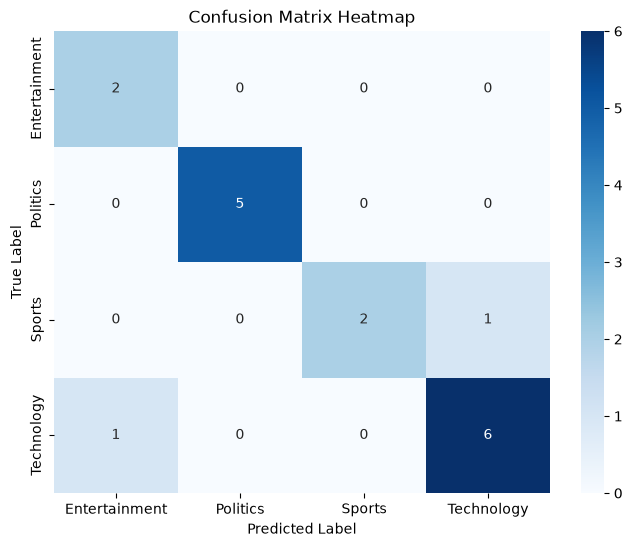

In [18]:
class_labels = np.unique(y_test)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
user